In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

IMG = Path("../images")
IMG.mkdir(exist_ok=True)

df = pd.read_csv("../data/processed/accidents_clean.csv",
                 parse_dates=["date", "datetime"])
print("Shape:", df.shape)


Shape: (20000, 33)


In [ ]:
#Accidents by Hour
plt.figure(figsize=(12,5))
sns.countplot(data=df, x="hour", color="#2E86AB")
plt.title("Accidents by Hour of Day", fontsize=14, weight="bold")
plt.xlabel("Hour"); plt.ylabel("Accidents")
plt.tight_layout()
plt.savefig(IMG/"01_hourly.png", bbox_inches="tight")
plt.show()

<Figure size 1320x550 with 1 Axes>

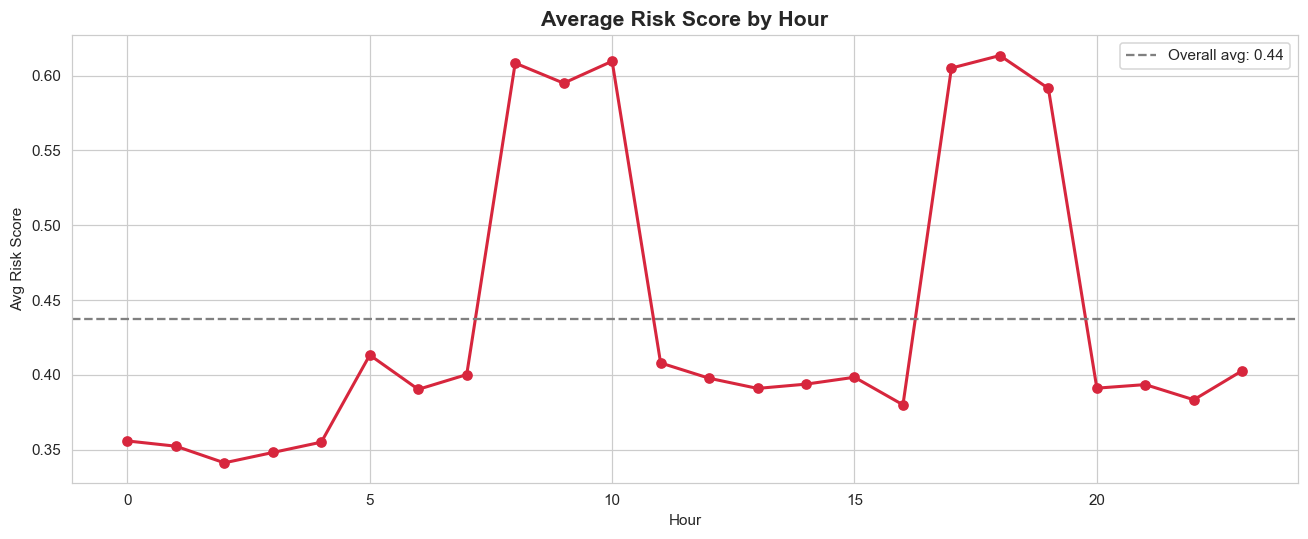

In [ ]:
#Avg Risk by Hour
hourly = df.groupby("hour")["risk_score"].mean()

plt.figure(figsize=(12,5))
plt.plot(hourly.index, hourly.values, marker="o", color="#D7263D", linewidth=2)
plt.axhline(df["risk_score"].mean(), linestyle="--", color="gray",
            label=f"Overall avg: {df['risk_score'].mean():.2f}")
plt.title("Average Risk Score by Hour", fontsize=14, weight="bold")
plt.xlabel("Hour"); plt.ylabel("Avg Risk Score")
plt.legend()
plt.tight_layout()
plt.savefig(IMG/"02_risk_by_hour.png", bbox_inches="tight")
plt.show()

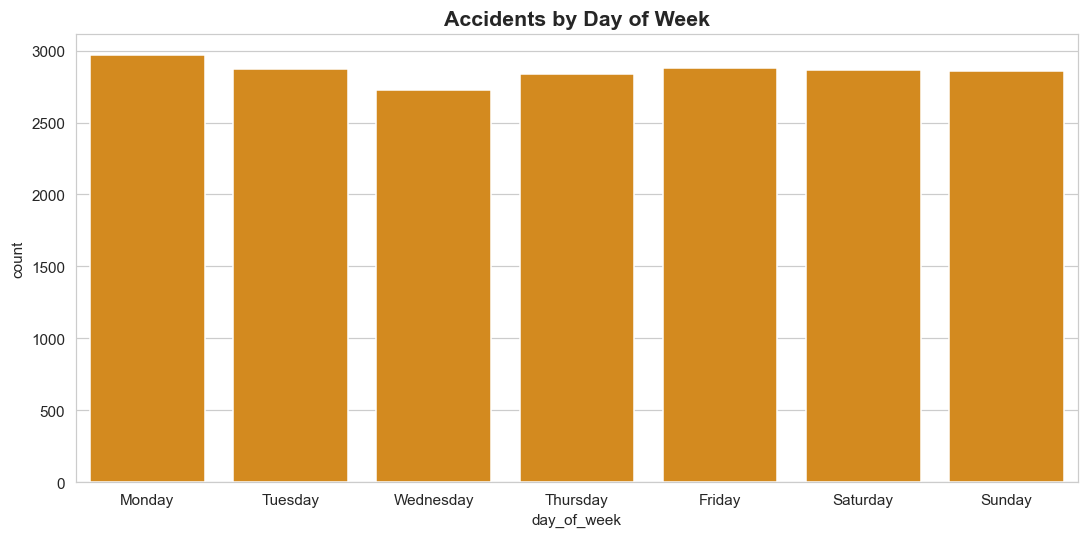

In [ ]:
#Day of Week
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="day_of_week", order=order, color="#F18F01")
plt.title("Accidents by Day of Week", fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(IMG/"03_dayofweek.png", bbox_inches="tight")
plt.show()

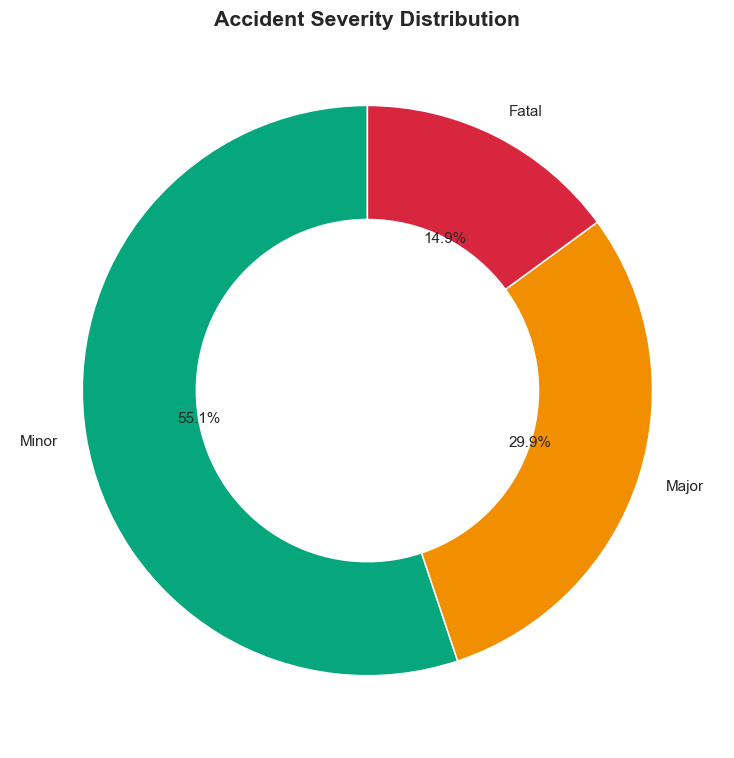

In [5]:
#Severity donut
sev = df["accident_severity"].value_counts()
colors = ["#06A77D","#F18F01","#D7263D"]  # Minor, Major, Fatal

plt.figure(figsize=(7,7))
plt.pie(sev, labels=sev.index, autopct="%1.1f%%", startangle=90,
        colors=colors, wedgeprops=dict(width=0.4, edgecolor="white"))
plt.title("Accident Severity Distribution", fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(IMG/"04_severity.png", bbox_inches="tight")
plt.show()

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_5852\2816113928.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weather_risk.index, y=weather_risk.values,


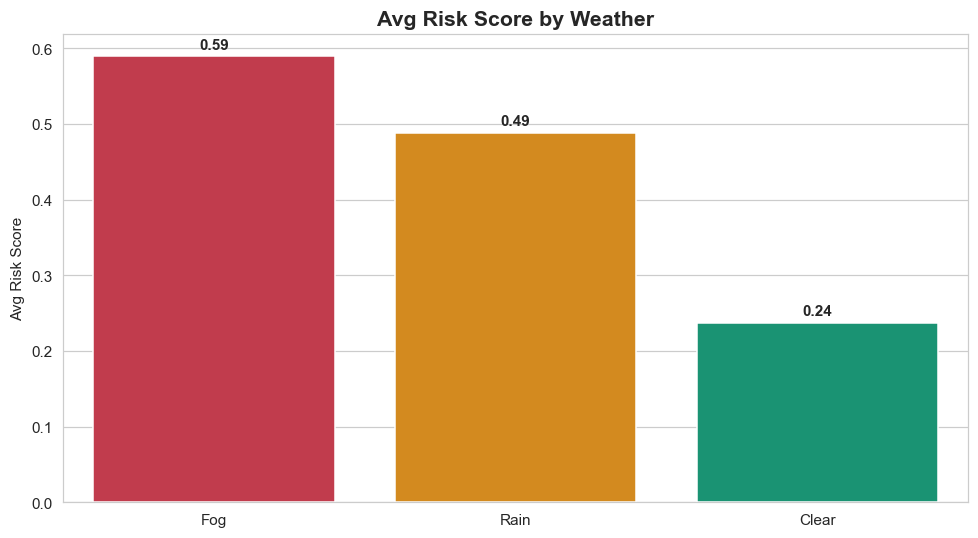

In [6]:
#Weather vs Avg Risk
weather_risk = df.groupby("weather")["risk_score"].mean().sort_values(ascending=False)

plt.figure(figsize=(9,5))
sns.barplot(x=weather_risk.index, y=weather_risk.values,
            palette=["#D7263D","#F18F01","#06A77D"])
plt.title("Avg Risk Score by Weather", fontsize=14, weight="bold")
plt.ylabel("Avg Risk Score"); plt.xlabel("")
for i, v in enumerate(weather_risk.values):
    plt.text(i, v + 0.01, f"{v:.2f}", ha="center", weight="bold")
plt.tight_layout()
plt.savefig(IMG/"05_weather_risk.png", bbox_inches="tight")
plt.show()

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_5852\2180481213.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vis_risk.index, y=vis_risk.values,


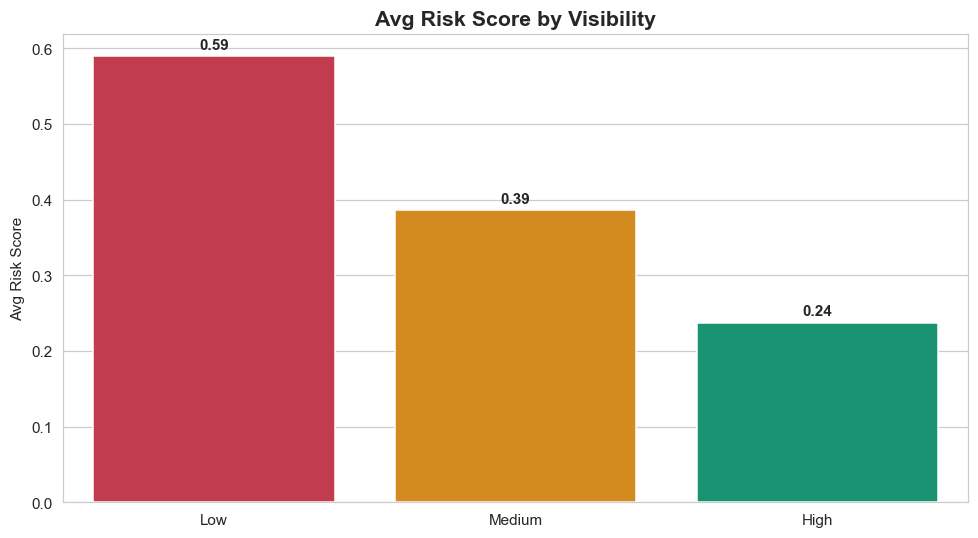

In [7]:
#Visibility vs Avg Risk
vis_order = ["Low","Medium","High"]
vis_risk = df.groupby("visibility")["risk_score"].mean().reindex(vis_order)

plt.figure(figsize=(9,5))
sns.barplot(x=vis_risk.index, y=vis_risk.values,
            palette=["#D7263D","#F18F01","#06A77D"])
plt.title("Avg Risk Score by Visibility", fontsize=14, weight="bold")
plt.ylabel("Avg Risk Score"); plt.xlabel("")
for i, v in enumerate(vis_risk.values):
    plt.text(i, v + 0.01, f"{v:.2f}", ha="center", weight="bold")
plt.tight_layout()
plt.savefig(IMG/"06_visibility_risk.png", bbox_inches="tight")
plt.show()

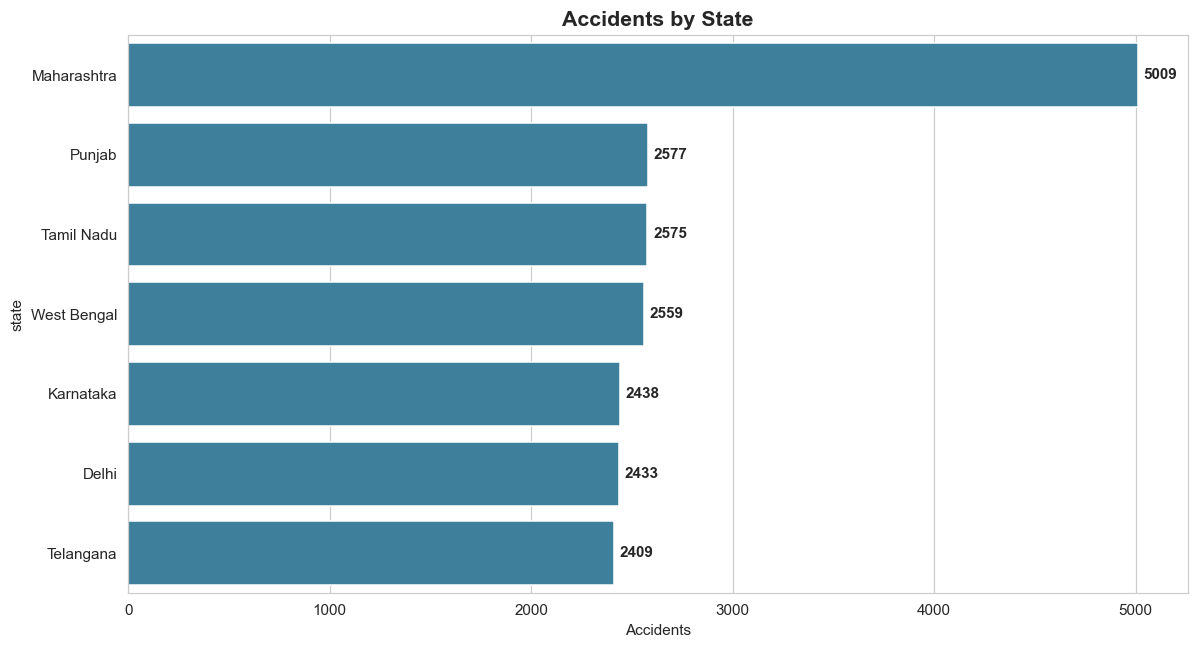

In [ ]:
#Top States 
top_states = df["state"].value_counts()

plt.figure(figsize=(11,6))
sns.barplot(x=top_states.values, y=top_states.index, color="#2E86AB")
plt.title("Accidents by State", fontsize=14, weight="bold")
plt.xlabel("Accidents")
for i, v in enumerate(top_states.values):
    plt.text(v + 30, i, str(v), va="center", weight="bold")
plt.tight_layout()
plt.savefig(IMG/"07_states.png", bbox_inches="tight")
plt.show()

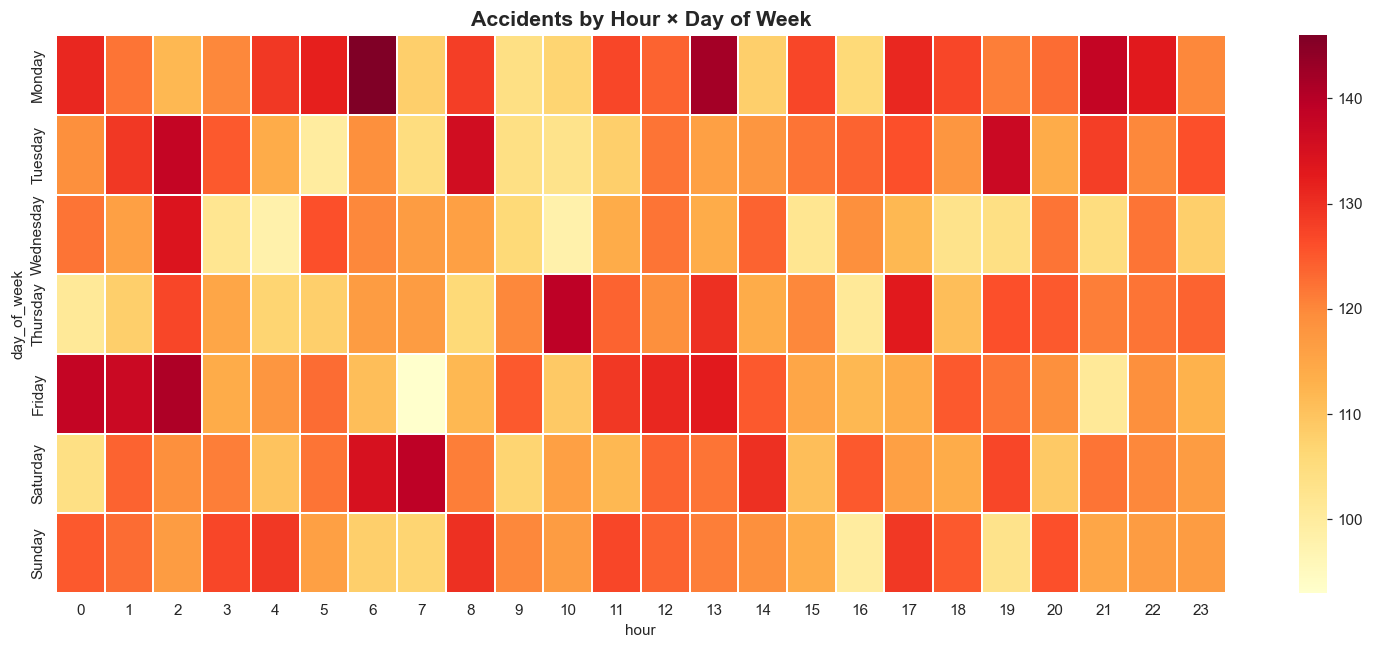

In [9]:
#Hour × Day heatmap
pivot = df.pivot_table(index="day_of_week", columns="hour",
                       values="accident_id", aggfunc="count").reindex(order)

plt.figure(figsize=(14,6))
sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.3)
plt.title("Accidents by Hour × Day of Week", fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(IMG/"08_hour_day_heatmap.png", bbox_inches="tight")
plt.show()

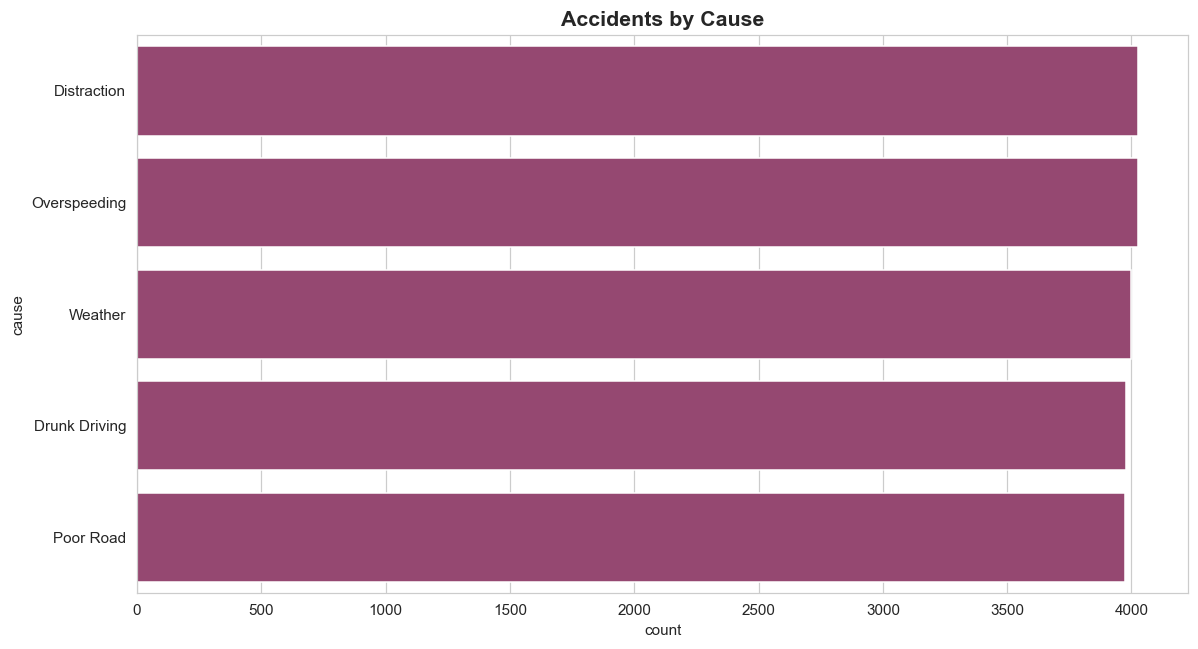

In [10]:
# Cause distribution
plt.figure(figsize=(11,6))
sns.countplot(data=df, y="cause",
              order=df["cause"].value_counts().index,
              color="#A23B72")
plt.title("Accidents by Cause", fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(IMG/"09_cause.png", bbox_inches="tight")
plt.show()

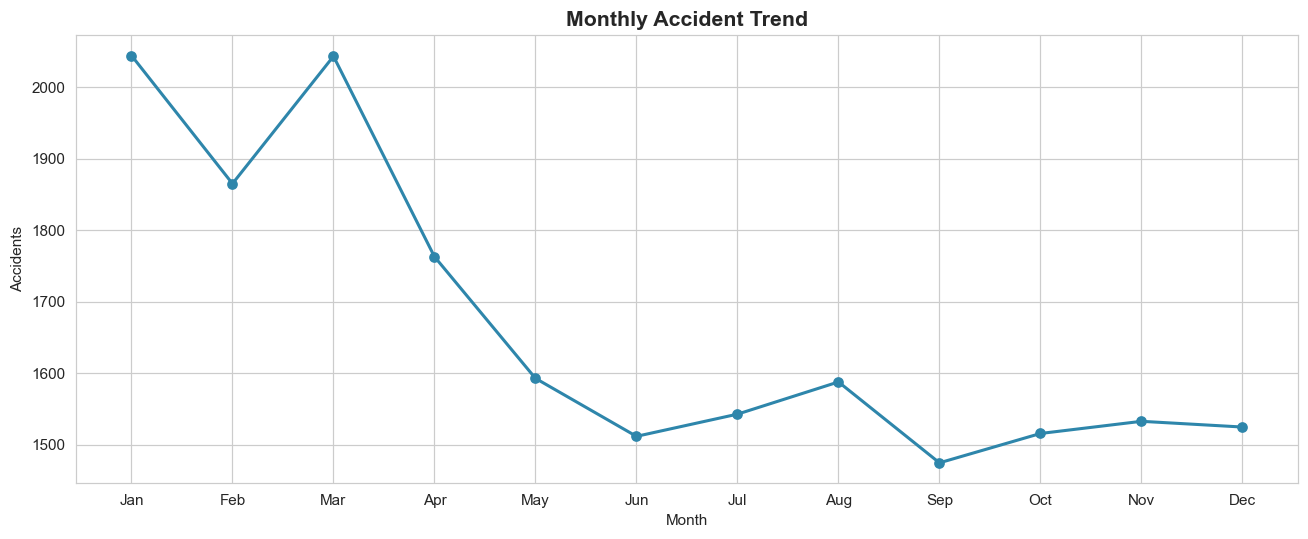

In [11]:
#  Monthly trend
monthly = df.groupby(["month","month_name"]).size().reset_index(name="accidents")
monthly = monthly.sort_values("month")

plt.figure(figsize=(12,5))
plt.plot(monthly["month_name"], monthly["accidents"],
         marker="o", color="#2E86AB", linewidth=2)
plt.title("Monthly Accident Trend", fontsize=14, weight="bold")
plt.xlabel("Month"); plt.ylabel("Accidents")
plt.tight_layout()
plt.savefig(IMG/"10_monthly.png", bbox_inches="tight")
plt.show()

In [12]:
import os
files = sorted(os.listdir(IMG))
print(f"{len(files)} images in {IMG}:")
for f in files:
    print(" -", f)

10 images in ..\images:
 - 01_hourly.png
 - 02_risk_by_hour.png
 - 03_dayofweek.png
 - 04_severity.png
 - 05_weather_risk.png
 - 06_visibility_risk.png
 - 07_states.png
 - 08_hour_day_heatmap.png
 - 09_cause.png
 - 10_monthly.png
